# **Getting Data and Importing Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from tensorflow import keras

In [2]:
df = pd.read_excel('Dataset#1.xlsx')

# **Data Exploration**


*   Checking the shape of the dataset
*   Looking for duplicates and null-values
*   Features data types
*   Number of outliers
*   The distribution of our target





In [3]:
df.head()

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.shape

(13611, 17)

In [5]:
df.describe() # Desc Stats

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [6]:
df.info() #Checking dtypes and Null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature1   13611 non-null  int64  
 1   Feature2   13611 non-null  float64
 2   Feature3   13611 non-null  float64
 3   Feature4   13611 non-null  float64
 4   Feature5   13611 non-null  float64
 5   Feature6   13611 non-null  float64
 6   Feature7   13611 non-null  int64  
 7   Feature8   13611 non-null  float64
 8   Feature9   13611 non-null  float64
 9   Feature10  13611 non-null  float64
 10  Feature11  13611 non-null  float64
 11  Feature12  13611 non-null  float64
 12  Feature13  13611 non-null  float64
 13  Feature14  13611 non-null  float64
 14  Feature15  13611 non-null  float64
 15  Feature16  13611 non-null  float64
 16  Class      13611 non-null  object 
dtypes: float64(14), int64(2), object(1)
memory usage: 1.8+ MB


In [7]:
df.duplicated().sum() # Number of duplicates

68

In [8]:
df.Class.value_counts() # Values of the target

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [9]:
pd.Series((df.Class.value_counts()/df.shape[0])*100) # Checking the imbalance

Class
DERMASON    26.052458
SIRA        19.366689
SEKER       14.892366
HOROZ       14.165014
CALI        11.975608
BARBUNYA     9.712732
BOMBAY       3.835133
Name: count, dtype: float64

In [10]:
def count_outliers(df): # Counting the outliers for each feature
  numeric_columns = df.select_dtypes(include=['number']).columns
  outlier_list=[]
  for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outlier_count = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    outlier_list.append((col,outlier_count))

  return outlier_list

In [11]:
count_outliers(df)

[('Feature1', 551),
 ('Feature2', 500),
 ('Feature3', 379),
 ('Feature4', 569),
 ('Feature5', 473),
 ('Feature6', 843),
 ('Feature7', 550),
 ('Feature8', 526),
 ('Feature9', 275),
 ('Feature10', 778),
 ('Feature11', 91),
 ('Feature12', 109),
 ('Feature13', 533),
 ('Feature14', 0),
 ('Feature15', 195),
 ('Feature16', 767)]

# **Data Visualization**

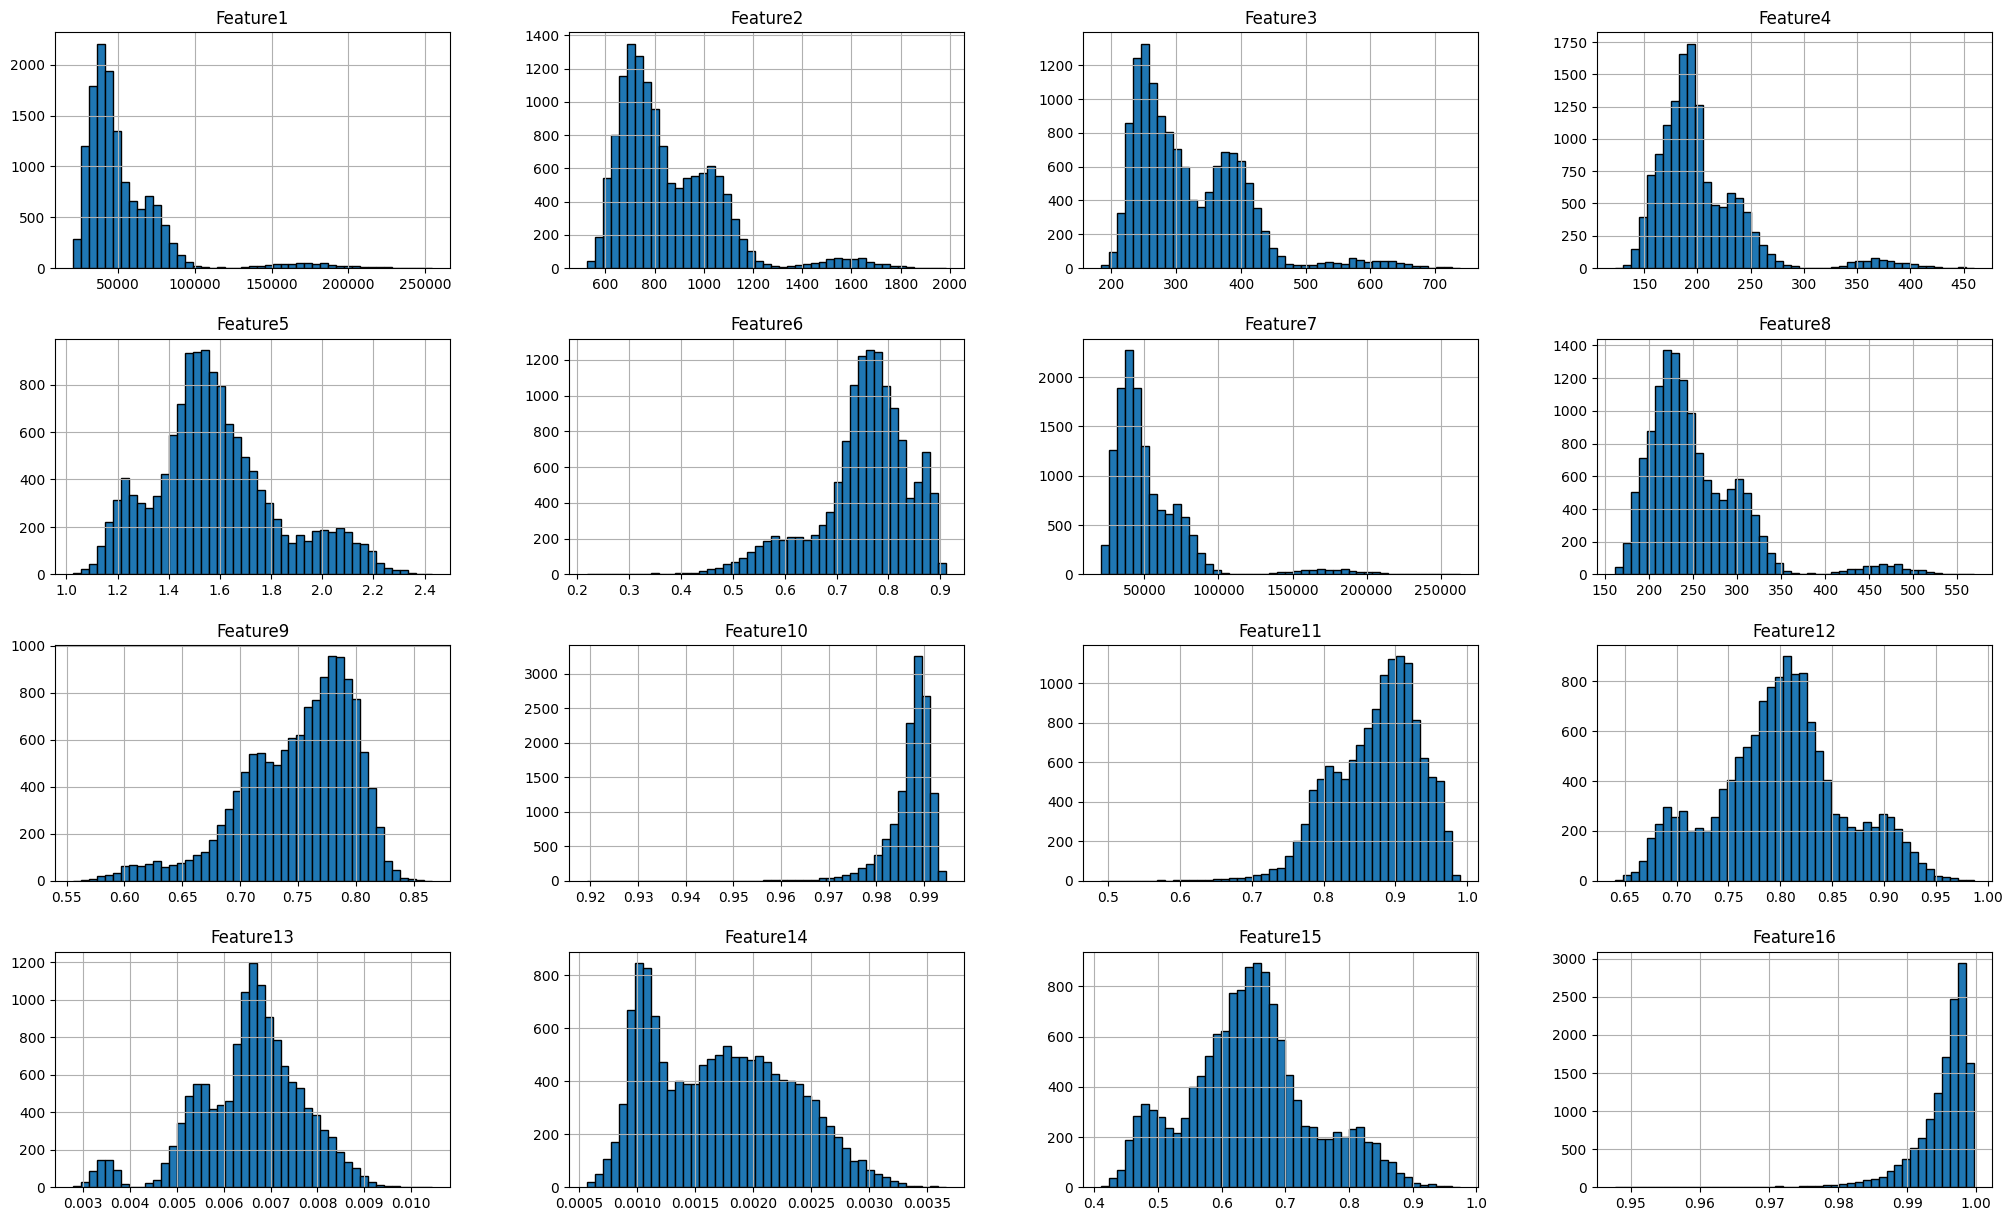

In [12]:
df.hist(bins=45,figsize=(25,15),ec='black')
plt.savefig('hist.jpg')

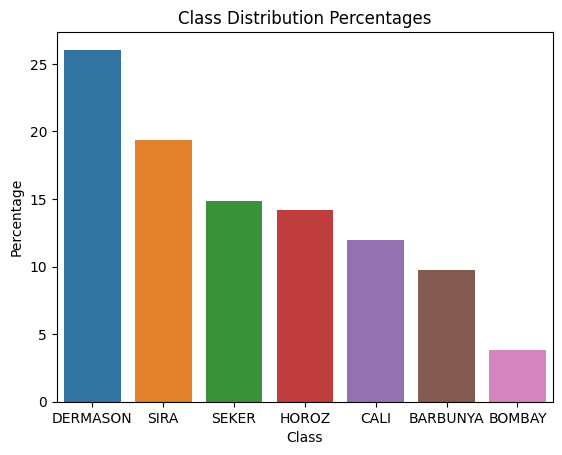

In [13]:
perc = pd.Series((df.Class.value_counts()/df.shape[0])*100)
ind = perc.index
perc = perc.reset_index(drop=True)
sns.barplot(x=ind,y=perc,hue=ind)
plt.xlabel('Class')
plt.ylabel('Percentage')
plt.title('Class Distribution Percentages')
plt.savefig('bar_chart.jpg')
plt.show()

In [14]:
numeric_cols = df.select_dtypes(include=['number']).columns
corr = df[numeric_cols].corr()
corr.style.background_gradient(cmap='Blues')

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16
Feature1,1.000000,0.966722,0.931834,0.951602,0.241735,0.267481,0.999939,0.984968,0.054345,-0.196585,-0.357530,-0.268067,-0.847958,-0.639291,-0.272145,-0.355721
Feature2,0.966722,1.000000,0.977338,0.913179,0.385276,0.391066,0.967689,0.991380,-0.021160,-0.303970,-0.547647,-0.406857,-0.864623,-0.767592,-0.408435,-0.429310
Feature3,0.931834,0.977338,1.000000,0.826052,0.550335,0.541972,0.932607,0.961733,-0.078062,-0.284302,-0.596358,-0.568377,-0.773609,-0.859238,-0.568185,-0.482527
Feature4,0.951602,0.913179,0.826052,1.000000,-0.009161,0.019574,0.951339,0.948539,0.145957,-0.155831,-0.210344,-0.015066,-0.947204,-0.471347,-0.019326,-0.263749
Feature5,0.241735,0.385276,0.550335,-0.009161,1.000000,0.924293,0.243301,0.303647,-0.370184,-0.267754,-0.766979,-0.987687,0.024593,-0.837841,-0.978592,-0.449264
Feature6,0.267481,0.391066,0.541972,0.019574,0.924293,1.000000,0.269255,0.318667,-0.319362,-0.297592,-0.722272,-0.970313,0.019920,-0.860141,-0.981058,-0.449354
Feature7,0.999939,0.967689,0.932607,0.951339,0.243301,0.269255,1.000000,0.985226,0.052564,-0.206191,-0.362083,-0.269922,-0.847950,-0.640862,-0.274024,-0.362049
Feature8,0.984968,0.991380,0.961733,0.948539,0.303647,0.318667,0.985226,1.000000,0.028383,-0.231648,-0.435945,-0.327650,-0.892741,-0.713069,-0.330389,-0.392512
Feature9,0.054345,-0.021160,-0.078062,0.145957,-0.370184,-0.319362,0.052564,0.028383,1.000000,0.191389,0.344411,0.354212,-0.141616,0.237956,0.347624,0.148502
Feature10,-0.196585,-0.303970,-0.284302,-0.155831,-0.267754,-0.297592,-0.206191,-0.231648,0.191389,1.000000,0.607150,0.303766,0.153388,0.343559,0.307662,0.702163


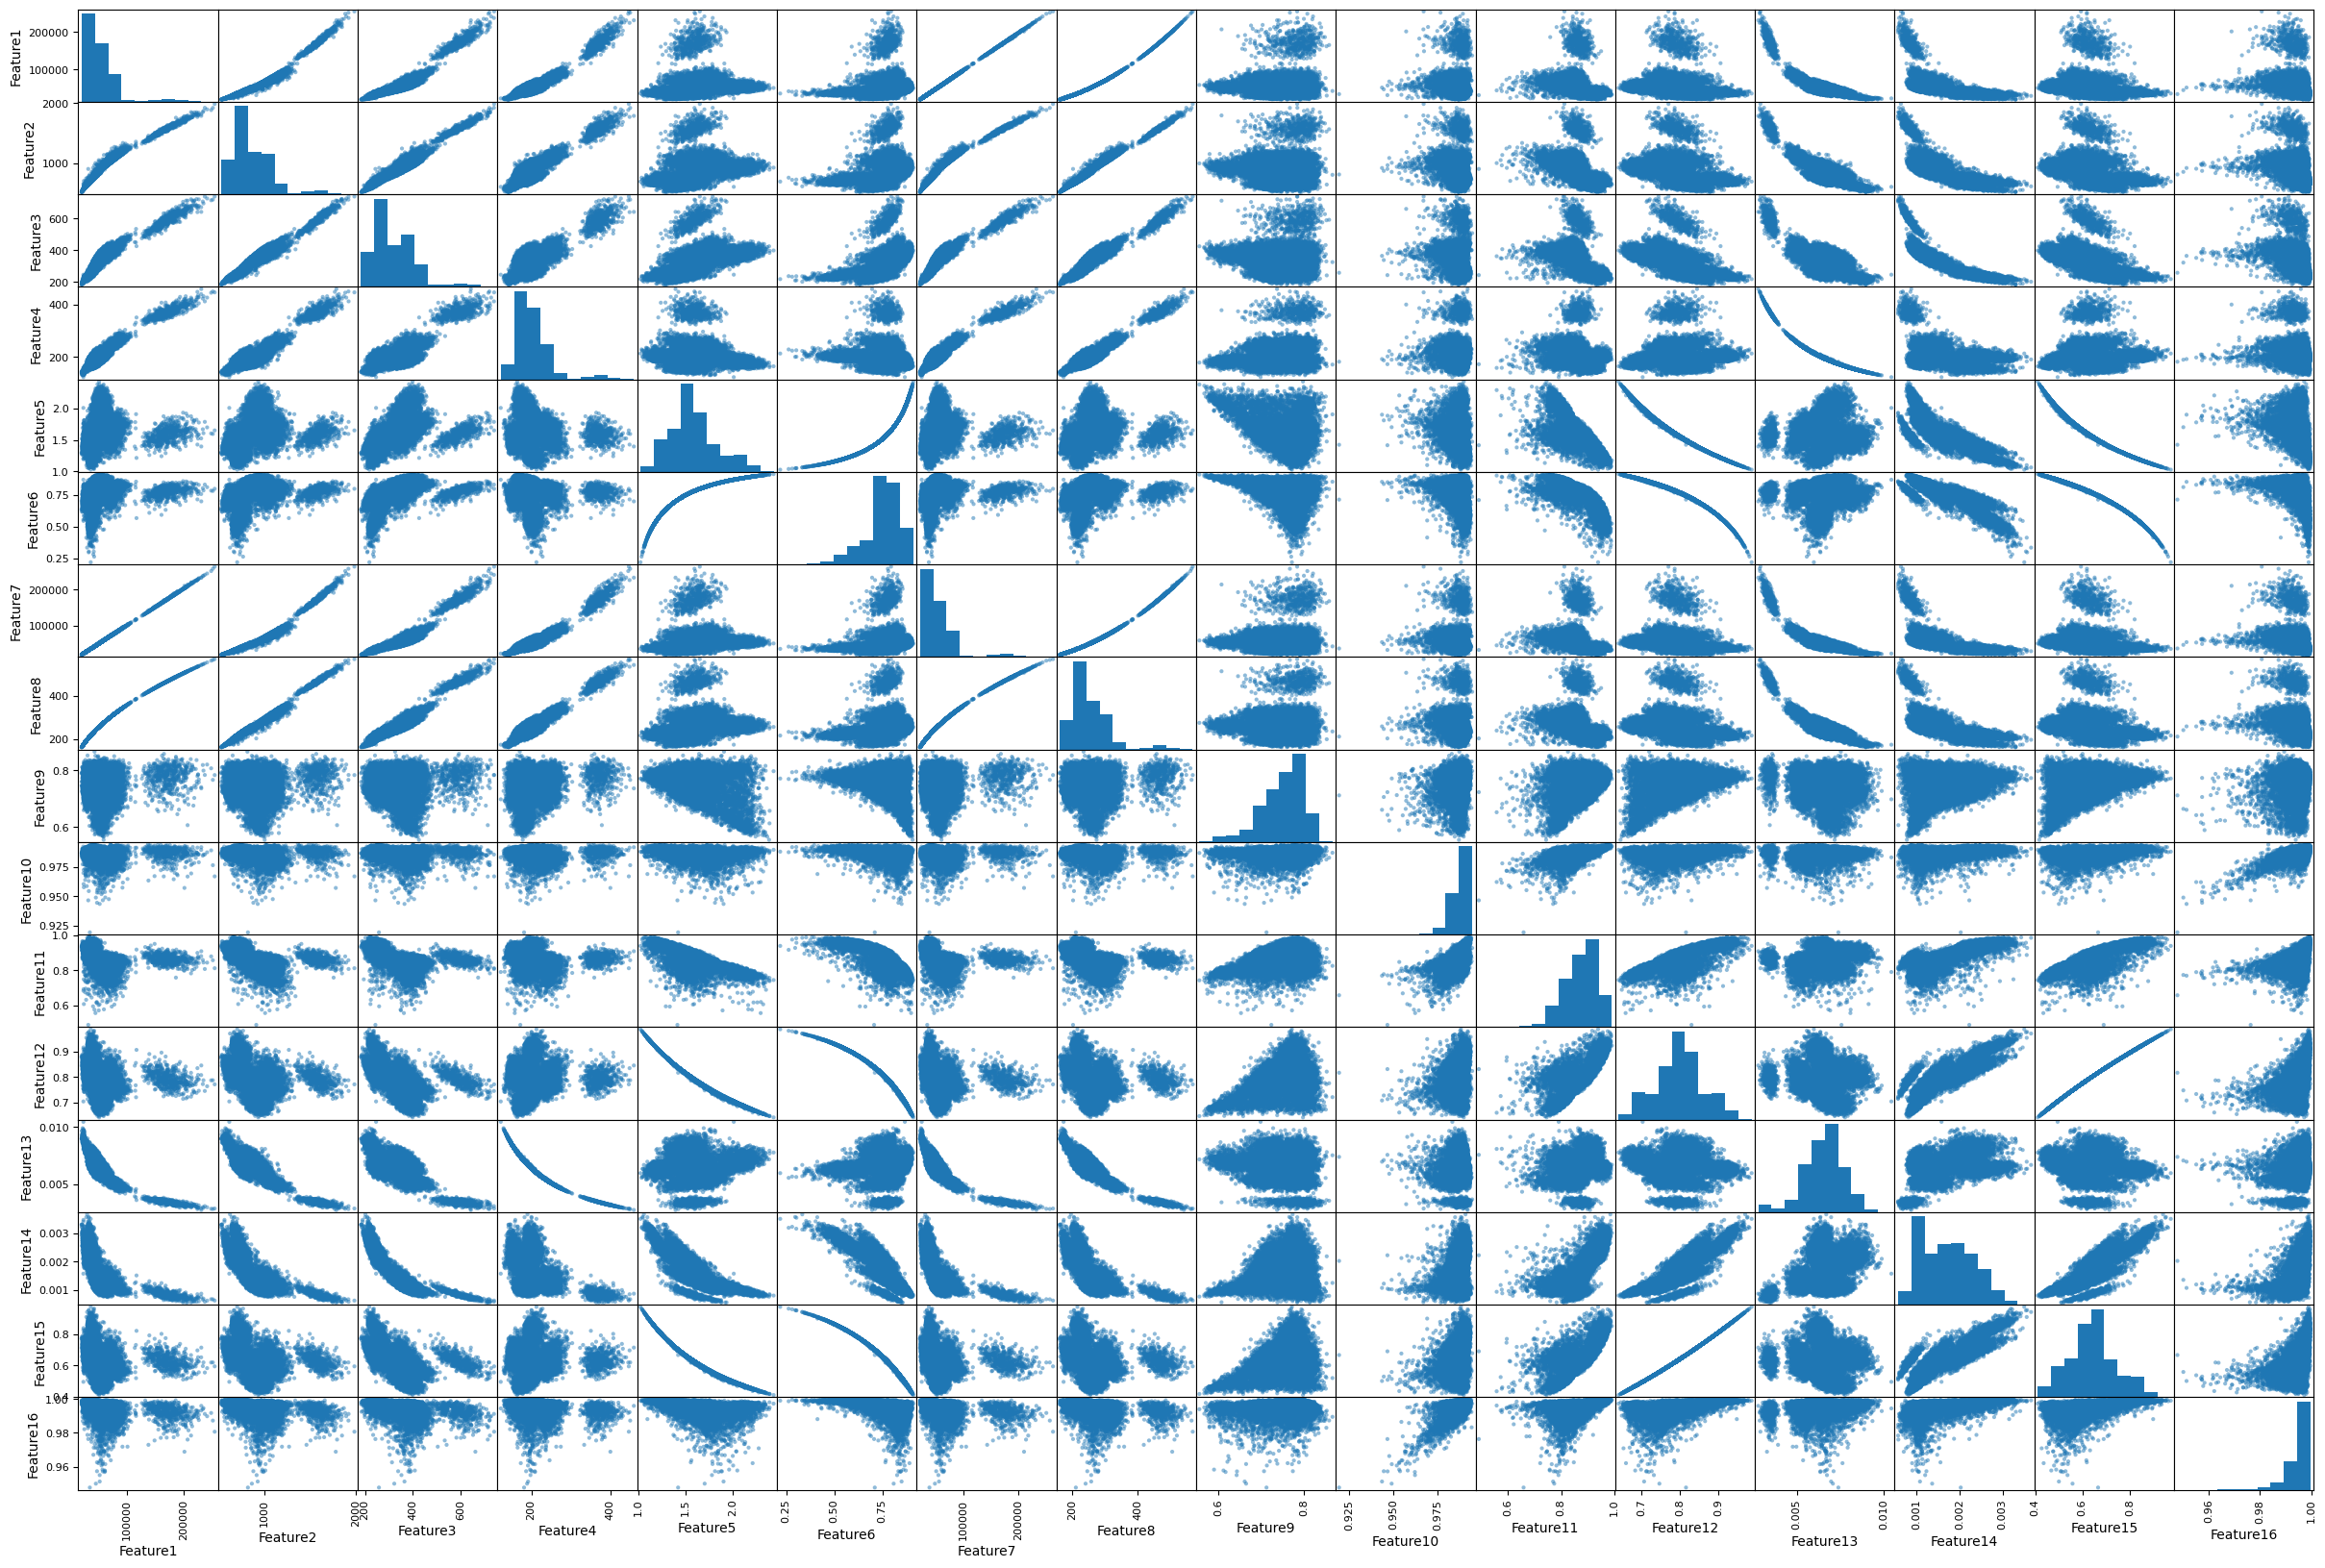

In [15]:
from pandas.plotting import scatter_matrix
scatter_matrix(df[numeric_cols], figsize=(30, 20))
plt.savefig('scatter_matrix.jpg')

# **Data Preprocessing**

In [16]:
df.drop_duplicates(inplace=True)

In [17]:
df['Feature17'] = df['Feature1'] * df['Feature2']
df['Feature18'] = df['Feature3']/df['Feature4']
df['Feature19'] = df['Feature3']/df['Feature2']
df['Feature20'] = df['Feature8']/df['Feature2']

In [18]:
col = df.columns.tolist()
col.remove('Class')
col.append('Class')
df = df[col] # Re-order the columns

In [19]:
from sklearn.preprocessing import StandardScaler
numeric_columns = df.reset_index(drop=True)._get_numeric_data().columns
scaler = StandardScaler()
scaler.fit(df[numeric_columns])
df[numeric_columns] = scaler.transform(df[numeric_columns])

In [20]:
df = pd.get_dummies(df,'Class',dtype=int)

In [21]:
x = df.iloc[:,:20]
y = df.iloc[:,20:]

In [22]:
from sklearn.decomposition import PCA
pca = PCA(n_components=12)
X = pca.fit_transform(x)

# **Modeling**

In [23]:
from sklearn.model_selection import train_test_split
X_train_, X_test, y_train_, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_, y_train_, test_size=0.15, random_state=42, stratify=y_train_)

In [24]:
from sklearn.neighbors import KNeighborsClassifier
model_1 = KNeighborsClassifier(p=1,weights='distance') # weights='distance' parameter to adjust the weights of the classes
model_1.fit(X_train, y_train)

KNeighborsClassifier(p=1, weights='distance')

In [25]:
y_val_pred = model_1.predict(X_valid)

In [26]:
from sklearn.metrics import f1_score
f1 = f1_score(y_valid, y_val_pred, average="macro")
f1

0.9384626489108302

In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
f1_macro = make_scorer(f1_score, average='macro')
param_grid = {'n_neighbors': [5, 10, 25, 50, 100]}
cv = GridSearchCV(model_1, param_grid, scoring=f1_macro)
cv.fit(X_train,y_train)
best_param = cv.best_params_
model_1.set_params(n_neighbors=best_param['n_neighbors'])

KNeighborsClassifier(n_neighbors=25, p=1, weights='distance')

In [28]:
model_1.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=25, p=1, weights='distance')

In [29]:
y_val_pred = model_1.predict(X_valid)

In [30]:
f1 = f1_score(y_valid, y_val_pred, average="macro")
f1 # Evaluating of validation data

0.9437066781766548

In [31]:
model_1.fit(X_train_,y_train_)

KNeighborsClassifier(n_neighbors=25, p=1, weights='distance')

In [32]:
y_test_pred = model_1.predict(X_test)

In [33]:
f1_1 = f1_score(y_test, y_test_pred, average='macro')
f1_1 # evaluating on test data and checking the generalization

0.9436300403497884

In [34]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.97      0.90      0.93       198
           1       1.00      1.00      1.00        78
           2       0.96      0.93      0.95       245
           3       0.95      0.90      0.93       532
           4       0.95      0.96      0.96       279
           5       0.96      0.94      0.95       304
           6       0.89      0.90      0.89       396

   micro avg       0.94      0.92      0.93      2032
   macro avg       0.95      0.93      0.94      2032
weighted avg       0.94      0.92      0.93      2032
 samples avg       0.92      0.92      0.92      2032



C:\Users\user\Desktop\Da350_project\ve350\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Confusion matrix to check if our model was predicting well

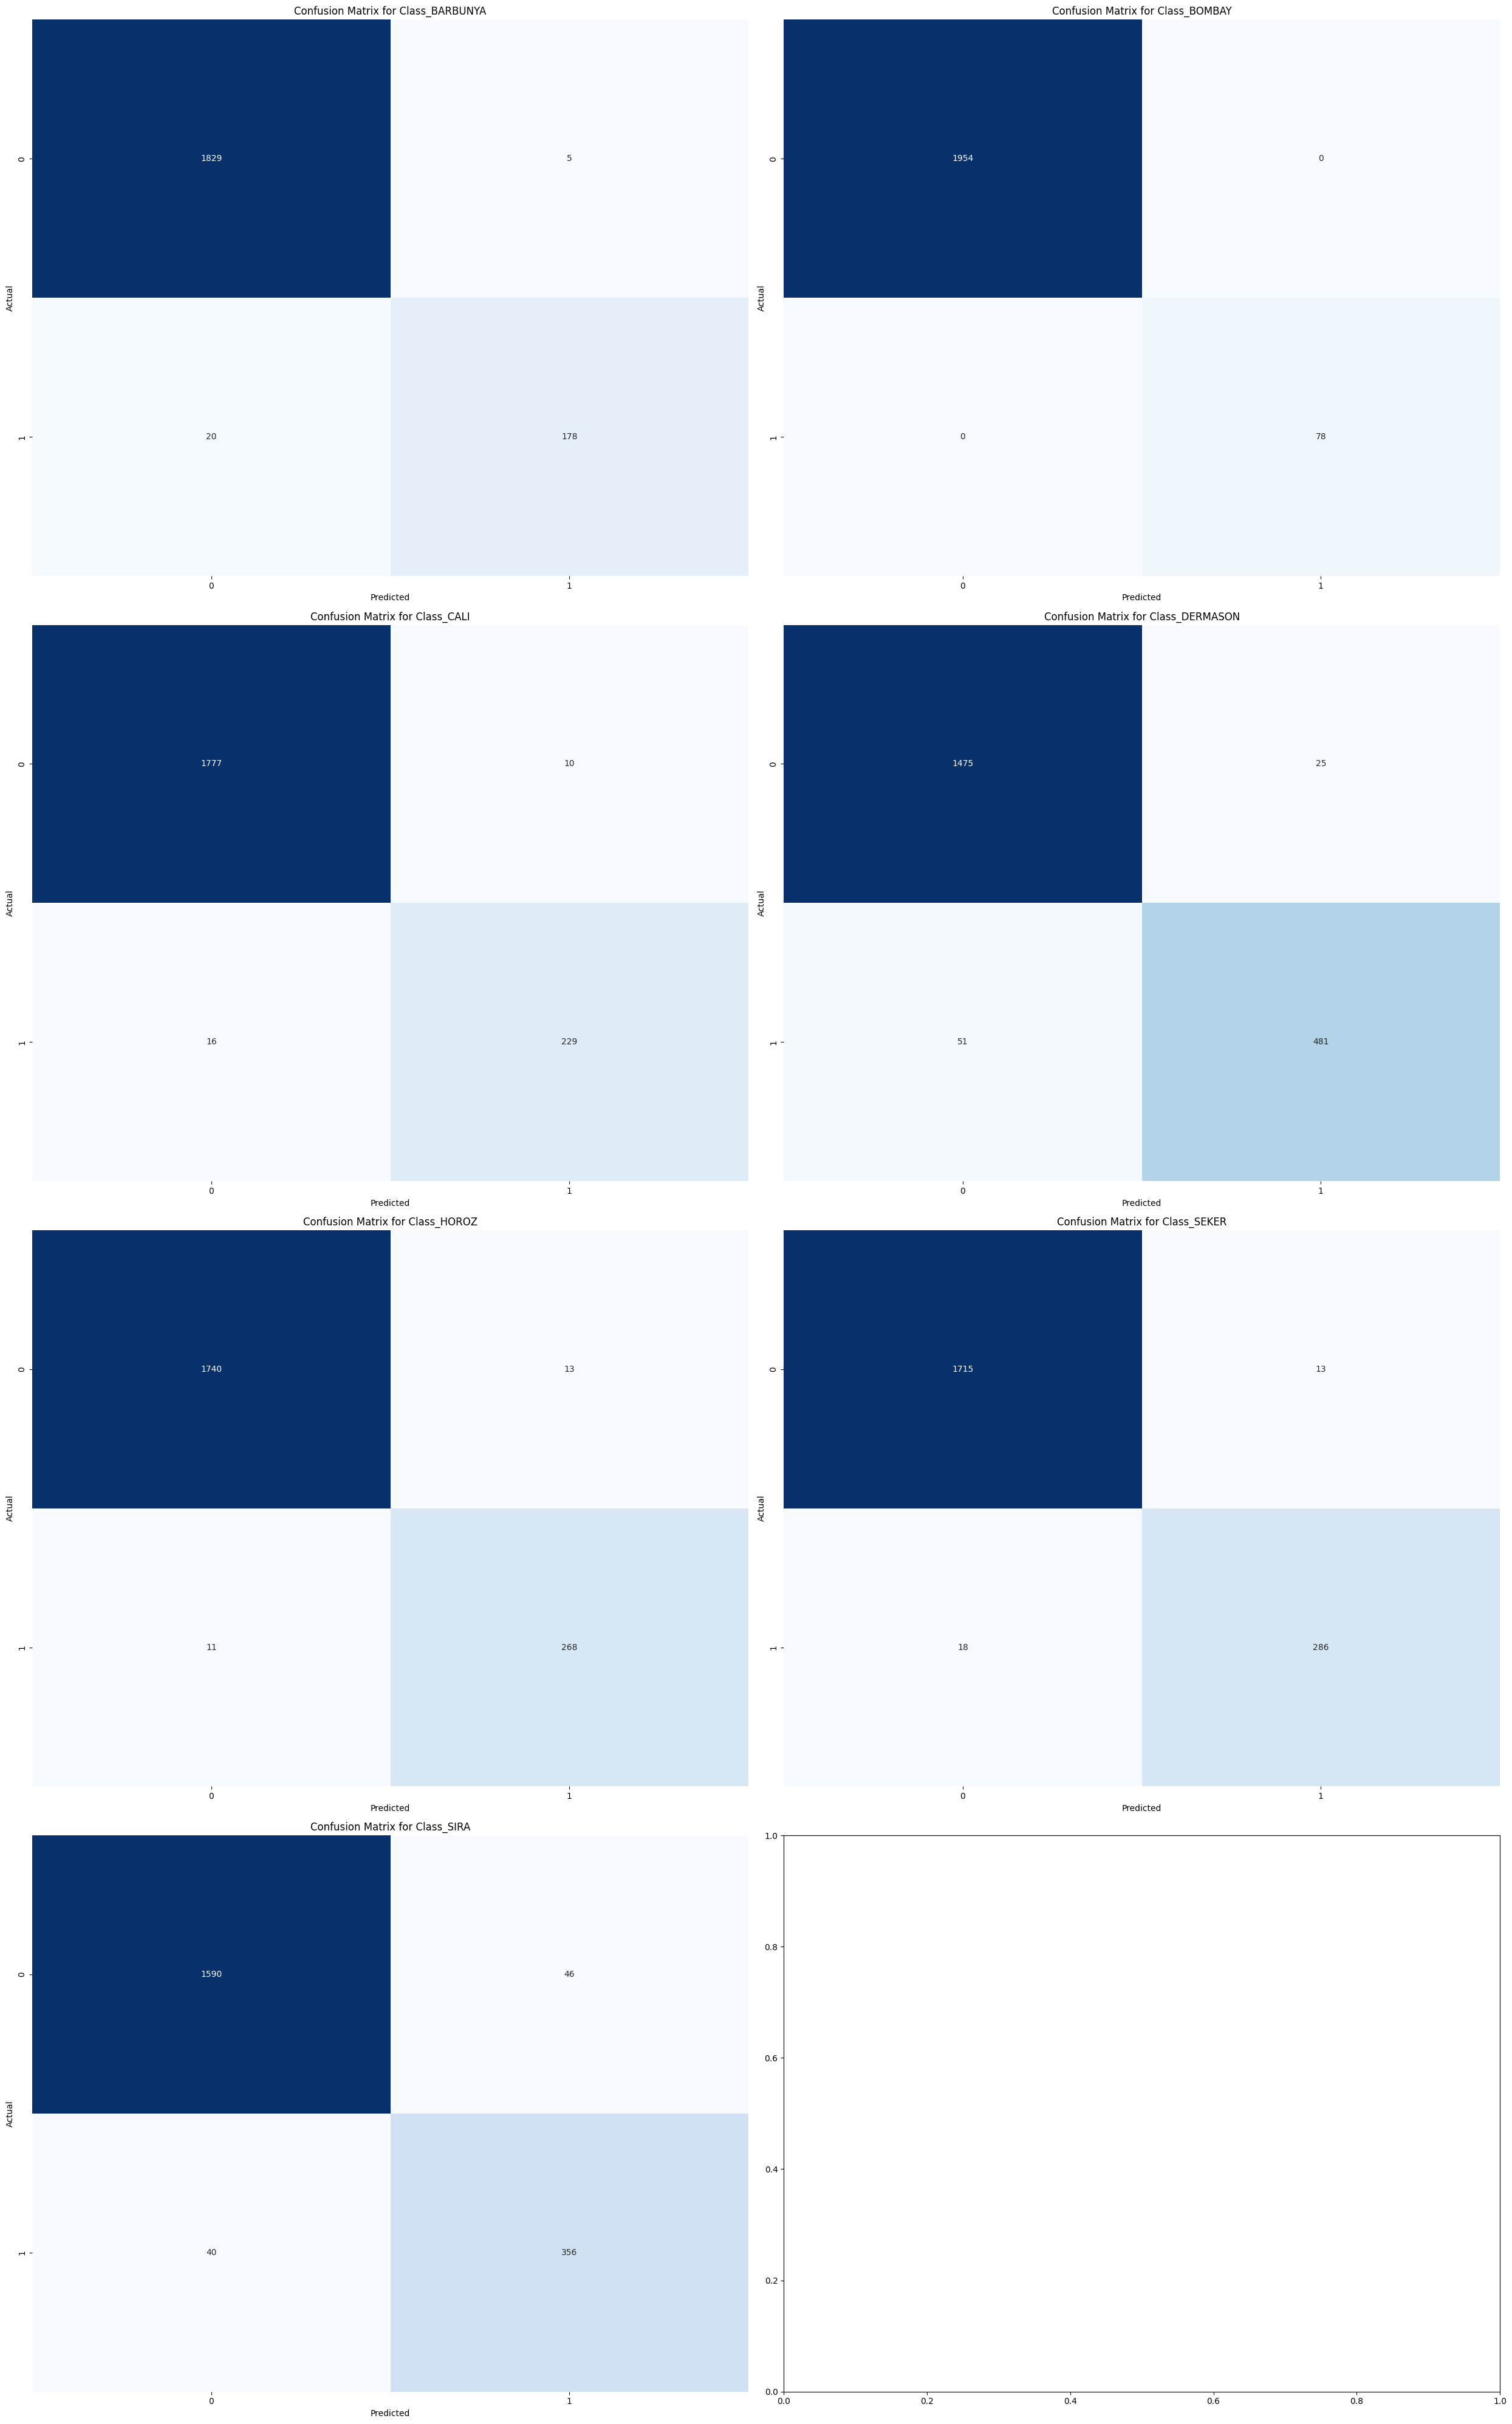

In [35]:
from sklearn.metrics import multilabel_confusion_matrix
conf_matrix = multilabel_confusion_matrix(y_test, y_test_pred)
labels = y.columns
n_cols = 2
n_rows = 4
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(25, 40))

for i, label in enumerate(labels):
    ax = axes[i // n_cols, i % n_cols]
    sns.heatmap(conf_matrix[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix for {label}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.savefig('conf_mat.jpg')
plt.tight_layout()
plt.show()

In [36]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(class_weight='balanced') # class_weight='balanced' adjust the weights based on the inverse of class frequencies
tree.fit(X_train,y_train)

DecisionTreeClassifier(class_weight='balanced')

In [37]:
y_val_pred2 = tree.predict(X_valid)

In [38]:
from sklearn.metrics import f1_score
f1 = f1_score(y_valid, y_val_pred2, average="macro")
f1

0.9100016292837515

In [39]:
params_grid = {'max_depth':[5,10,20,30,40],'min_samples_leaf':[5,10,15,20,25],'min_samples_split': [4,8,12,16,20]}
cv2 = GridSearchCV(tree, params_grid, scoring=f1_macro)
cv2.fit(X_train,y_train)
best_params = cv2.best_params_

In [40]:
tree.set_params(max_depth=best_params['max_depth'],min_samples_leaf=best_params['min_samples_leaf'],min_samples_split=best_params['min_samples_split'])
tree.fit(X_train,y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=10, min_samples_split=16)

In [41]:
y_val_pred2 = tree.predict(X_valid)

In [42]:
f1 = f1_score(y_valid, y_val_pred2, average="macro")
f1 # evaluating on validation data

0.924865094109553

In [43]:
tree.fit(X_train_,y_train_)

DecisionTreeClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=10, min_samples_split=16)

In [44]:
y_test_pred2 = tree.predict(X_test)
f1_2 = f1_score(y_test, y_test_pred2, average="macro")
f1_2 # evaluating on test data and checking the generalization

0.9174125039554164

In [45]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred2))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90       198
           1       1.00      0.99      0.99        78
           2       0.95      0.90      0.93       245
           3       0.95      0.85      0.90       532
           4       0.93      0.95      0.94       279
           5       0.91      0.94      0.93       304
           6       0.84      0.85      0.84       396

   micro avg       0.91      0.89      0.90      2032
   macro avg       0.92      0.91      0.92      2032
weighted avg       0.91      0.89      0.90      2032
 samples avg       0.89      0.89      0.89      2032



C:\Users\user\Desktop\Da350_project\ve350\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


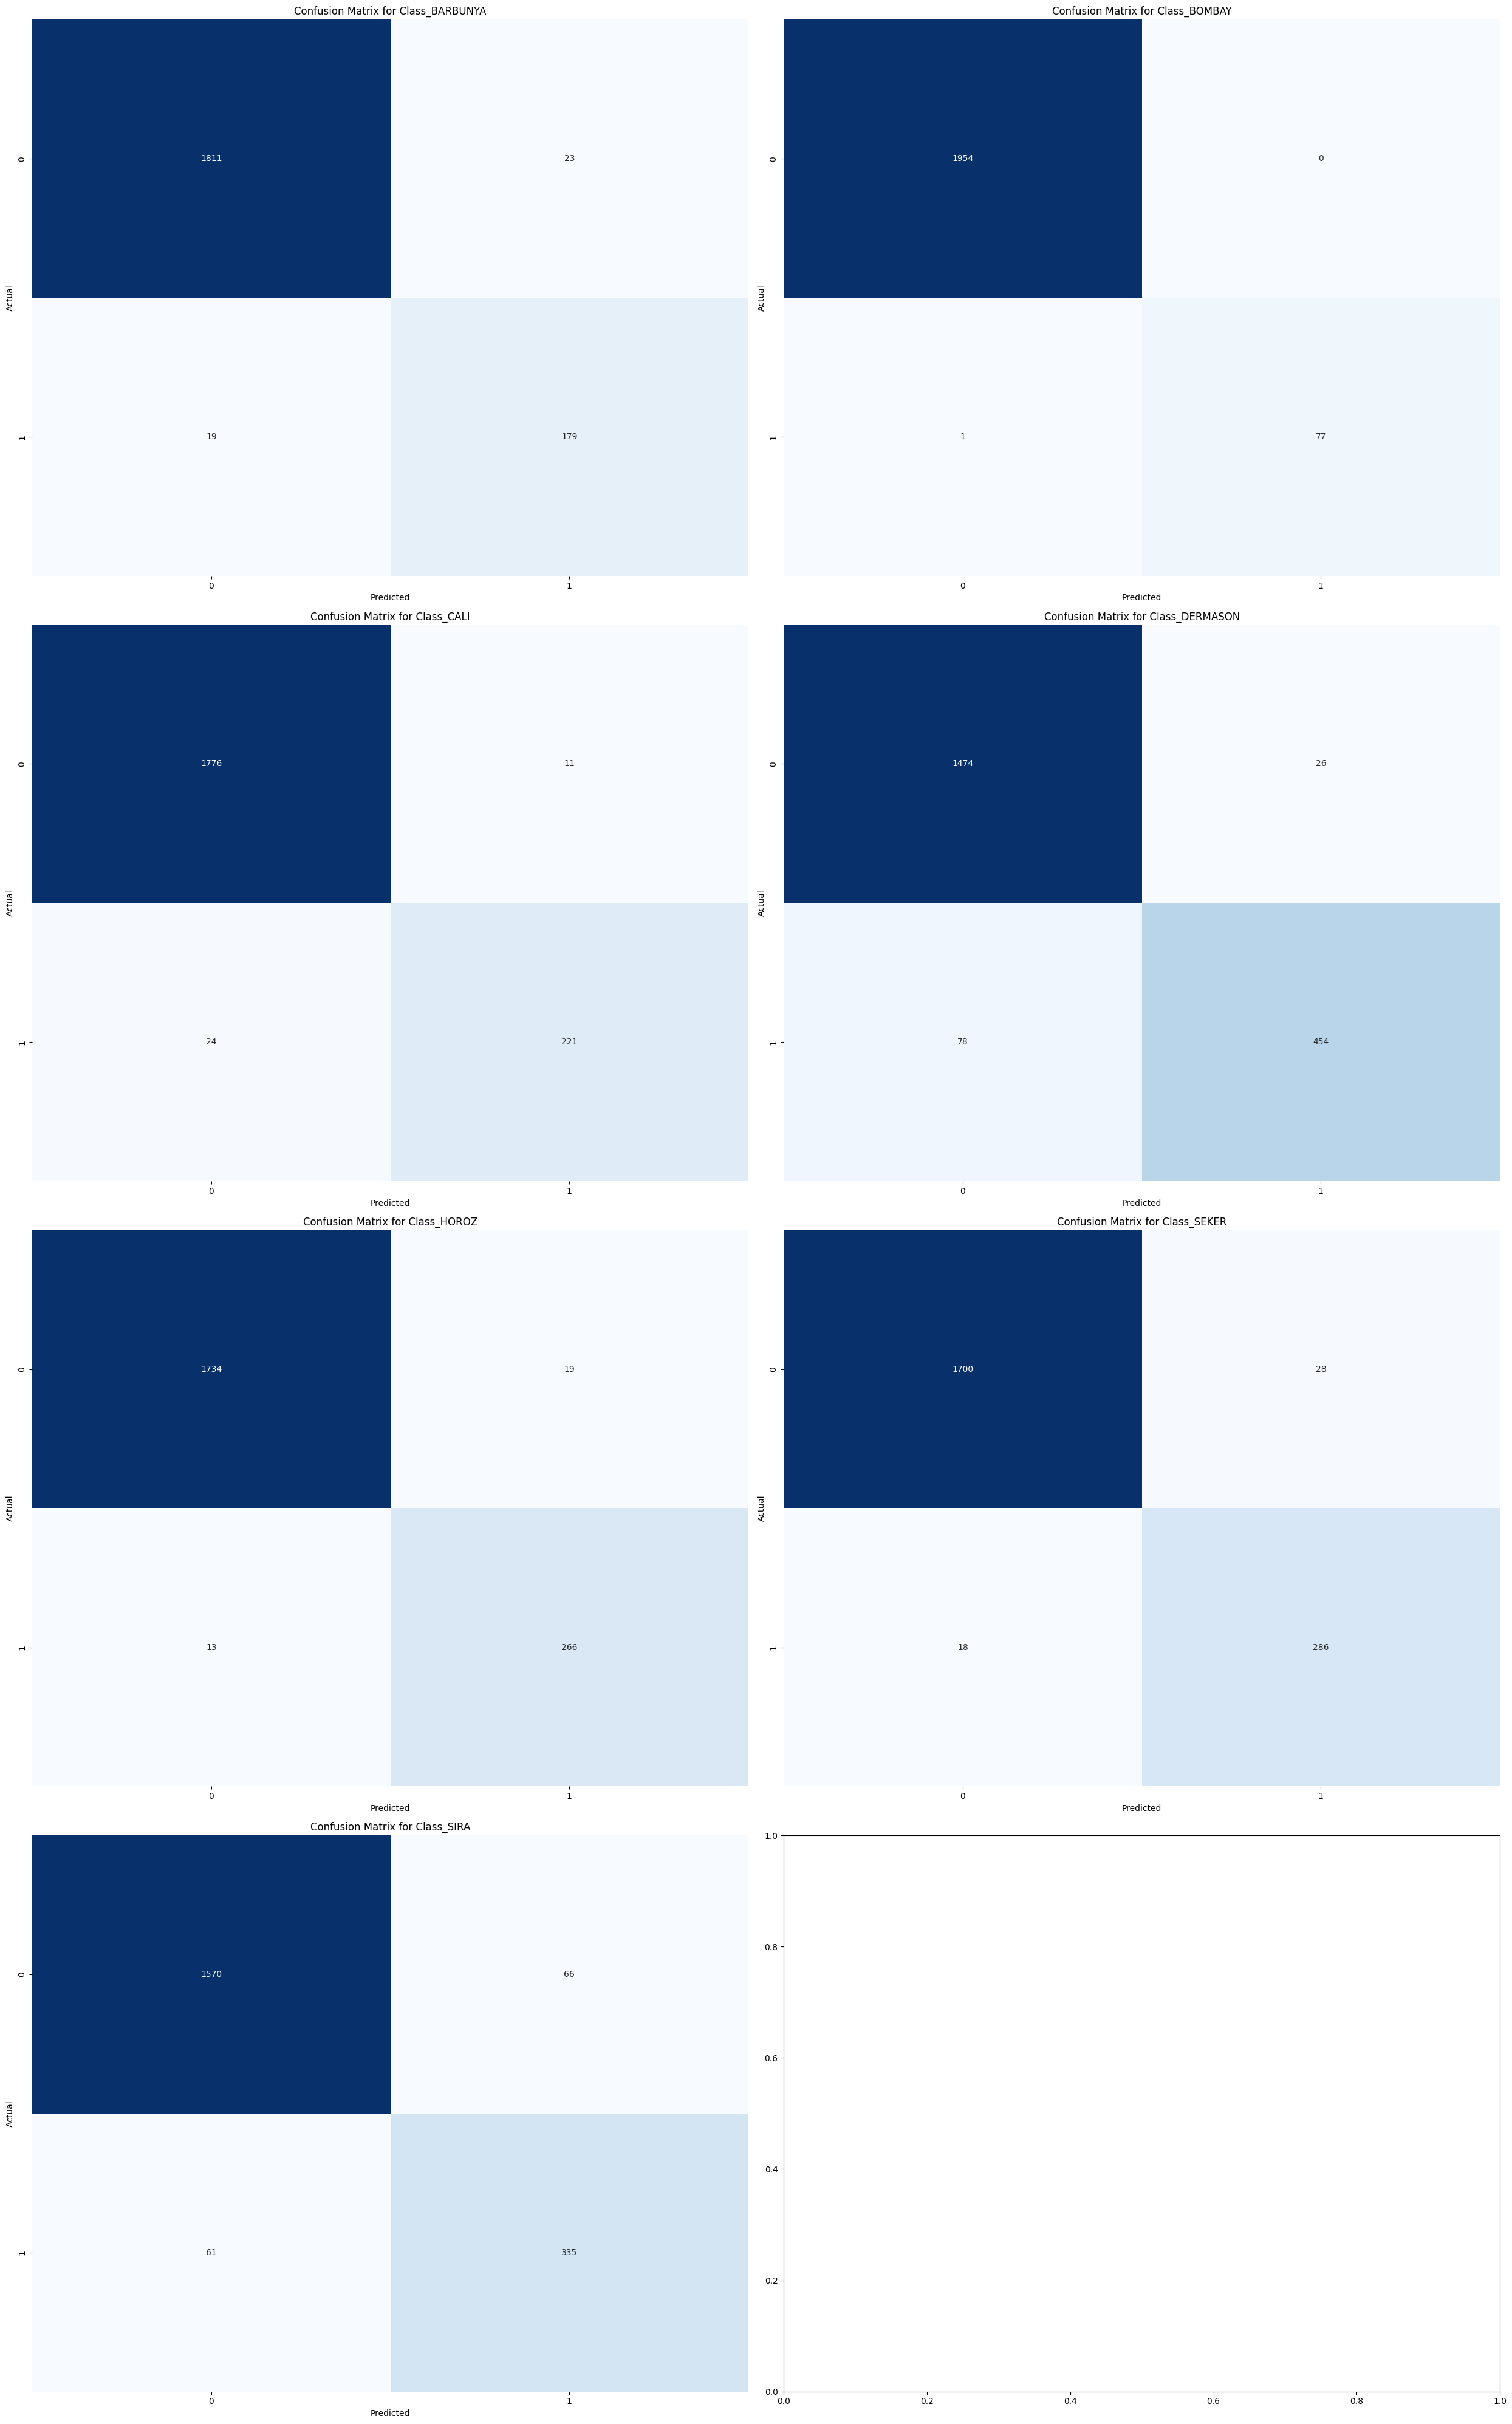

In [63]:
from sklearn.metrics import multilabel_confusion_matrix
conf_matrix = multilabel_confusion_matrix(y_test, y_test_pred2)
labels = y.columns
n_cols = 2
n_rows = 4
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(25, 40))

for i, label in enumerate(labels):
    ax = axes[i // n_cols, i % n_cols]
    sns.heatmap(conf_matrix[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix for {label}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

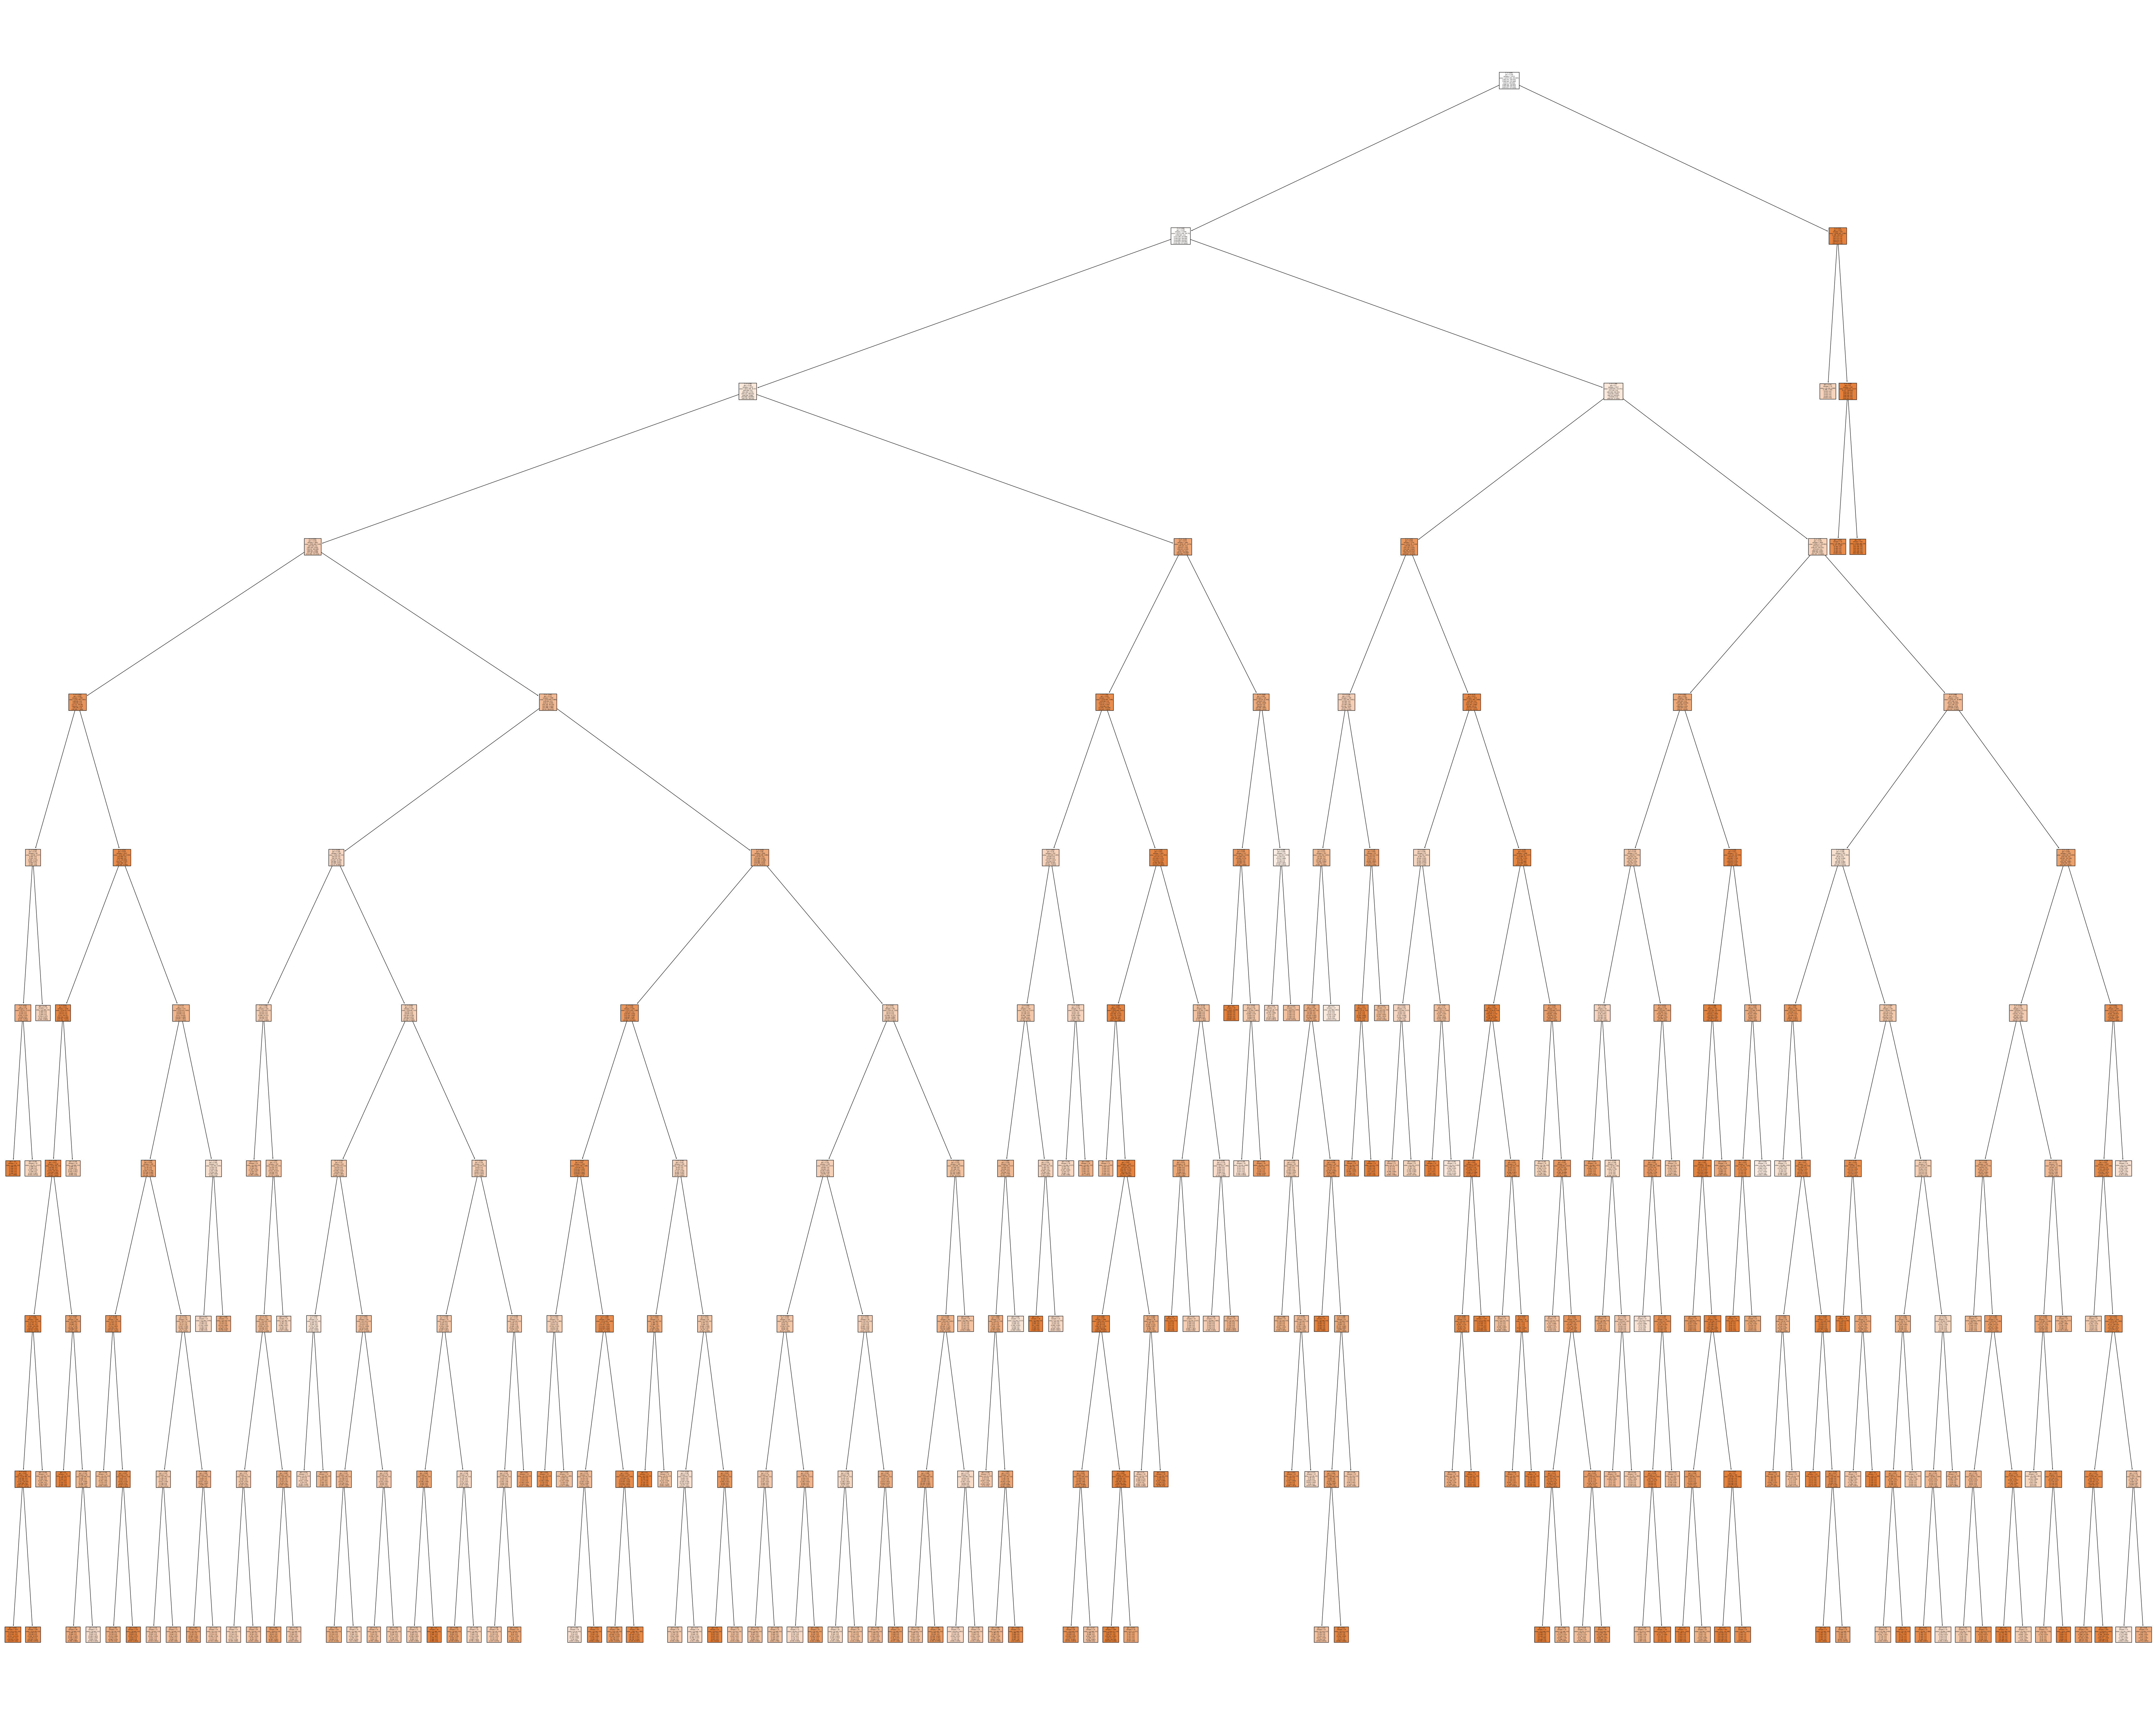

In [46]:
from sklearn.tree import plot_tree
X =pd.DataFrame(X)
fig = plt.figure(figsize=(100,80))
_ = plot_tree(tree,
                   feature_names=X.columns,
                   class_names=y.columns,
                   filled=True)
plt.savefig('tree.jpg') # plotting our decision tree

In [47]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(class_weight='balanced')
params_grid_ = {'max_depth':[5,10,20,30,40],'min_samples_split': [4,8,12,16,20]}
cv3 = GridSearchCV(rf,params_grid_,scoring=f1_macro)
cv3.fit(X_train,y_train)
best_params_ = cv3.best_params_
rf.set_params(max_depth=best_params_['max_depth'],min_samples_split=best_params_['min_samples_split'])

RandomForestClassifier(class_weight='balanced', max_depth=30,
                       min_samples_split=4)

In [48]:
rf.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', max_depth=30,
                       min_samples_split=4)

In [49]:
y_val_pred3 = rf.predict(X_valid)
f1 = f1_score(y_valid, y_val_pred3, average="macro")
f1 # evaluating on validation data

0.9394241259582369

In [50]:
rf.fit(X_train_,y_train_)

RandomForestClassifier(class_weight='balanced', max_depth=30,
                       min_samples_split=4)

In [51]:
y_test_pred3 = rf.predict(X_test)
f1_3 = f1_score(y_test, y_test_pred3, average="macro")
f1_3 # evaluating on test data and checking the generalization

0.9427478838371449

In [52]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred3))

              precision    recall  f1-score   support

           0       0.98      0.90      0.94       198
           1       1.00      1.00      1.00        78
           2       0.97      0.93      0.95       245
           3       0.95      0.89      0.92       532
           4       0.95      0.96      0.96       279
           5       0.96      0.94      0.95       304
           6       0.88      0.89      0.88       396

   micro avg       0.94      0.92      0.93      2032
   macro avg       0.96      0.93      0.94      2032
weighted avg       0.95      0.92      0.93      2032
 samples avg       0.92      0.92      0.92      2032



C:\Users\user\Desktop\Da350_project\ve350\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


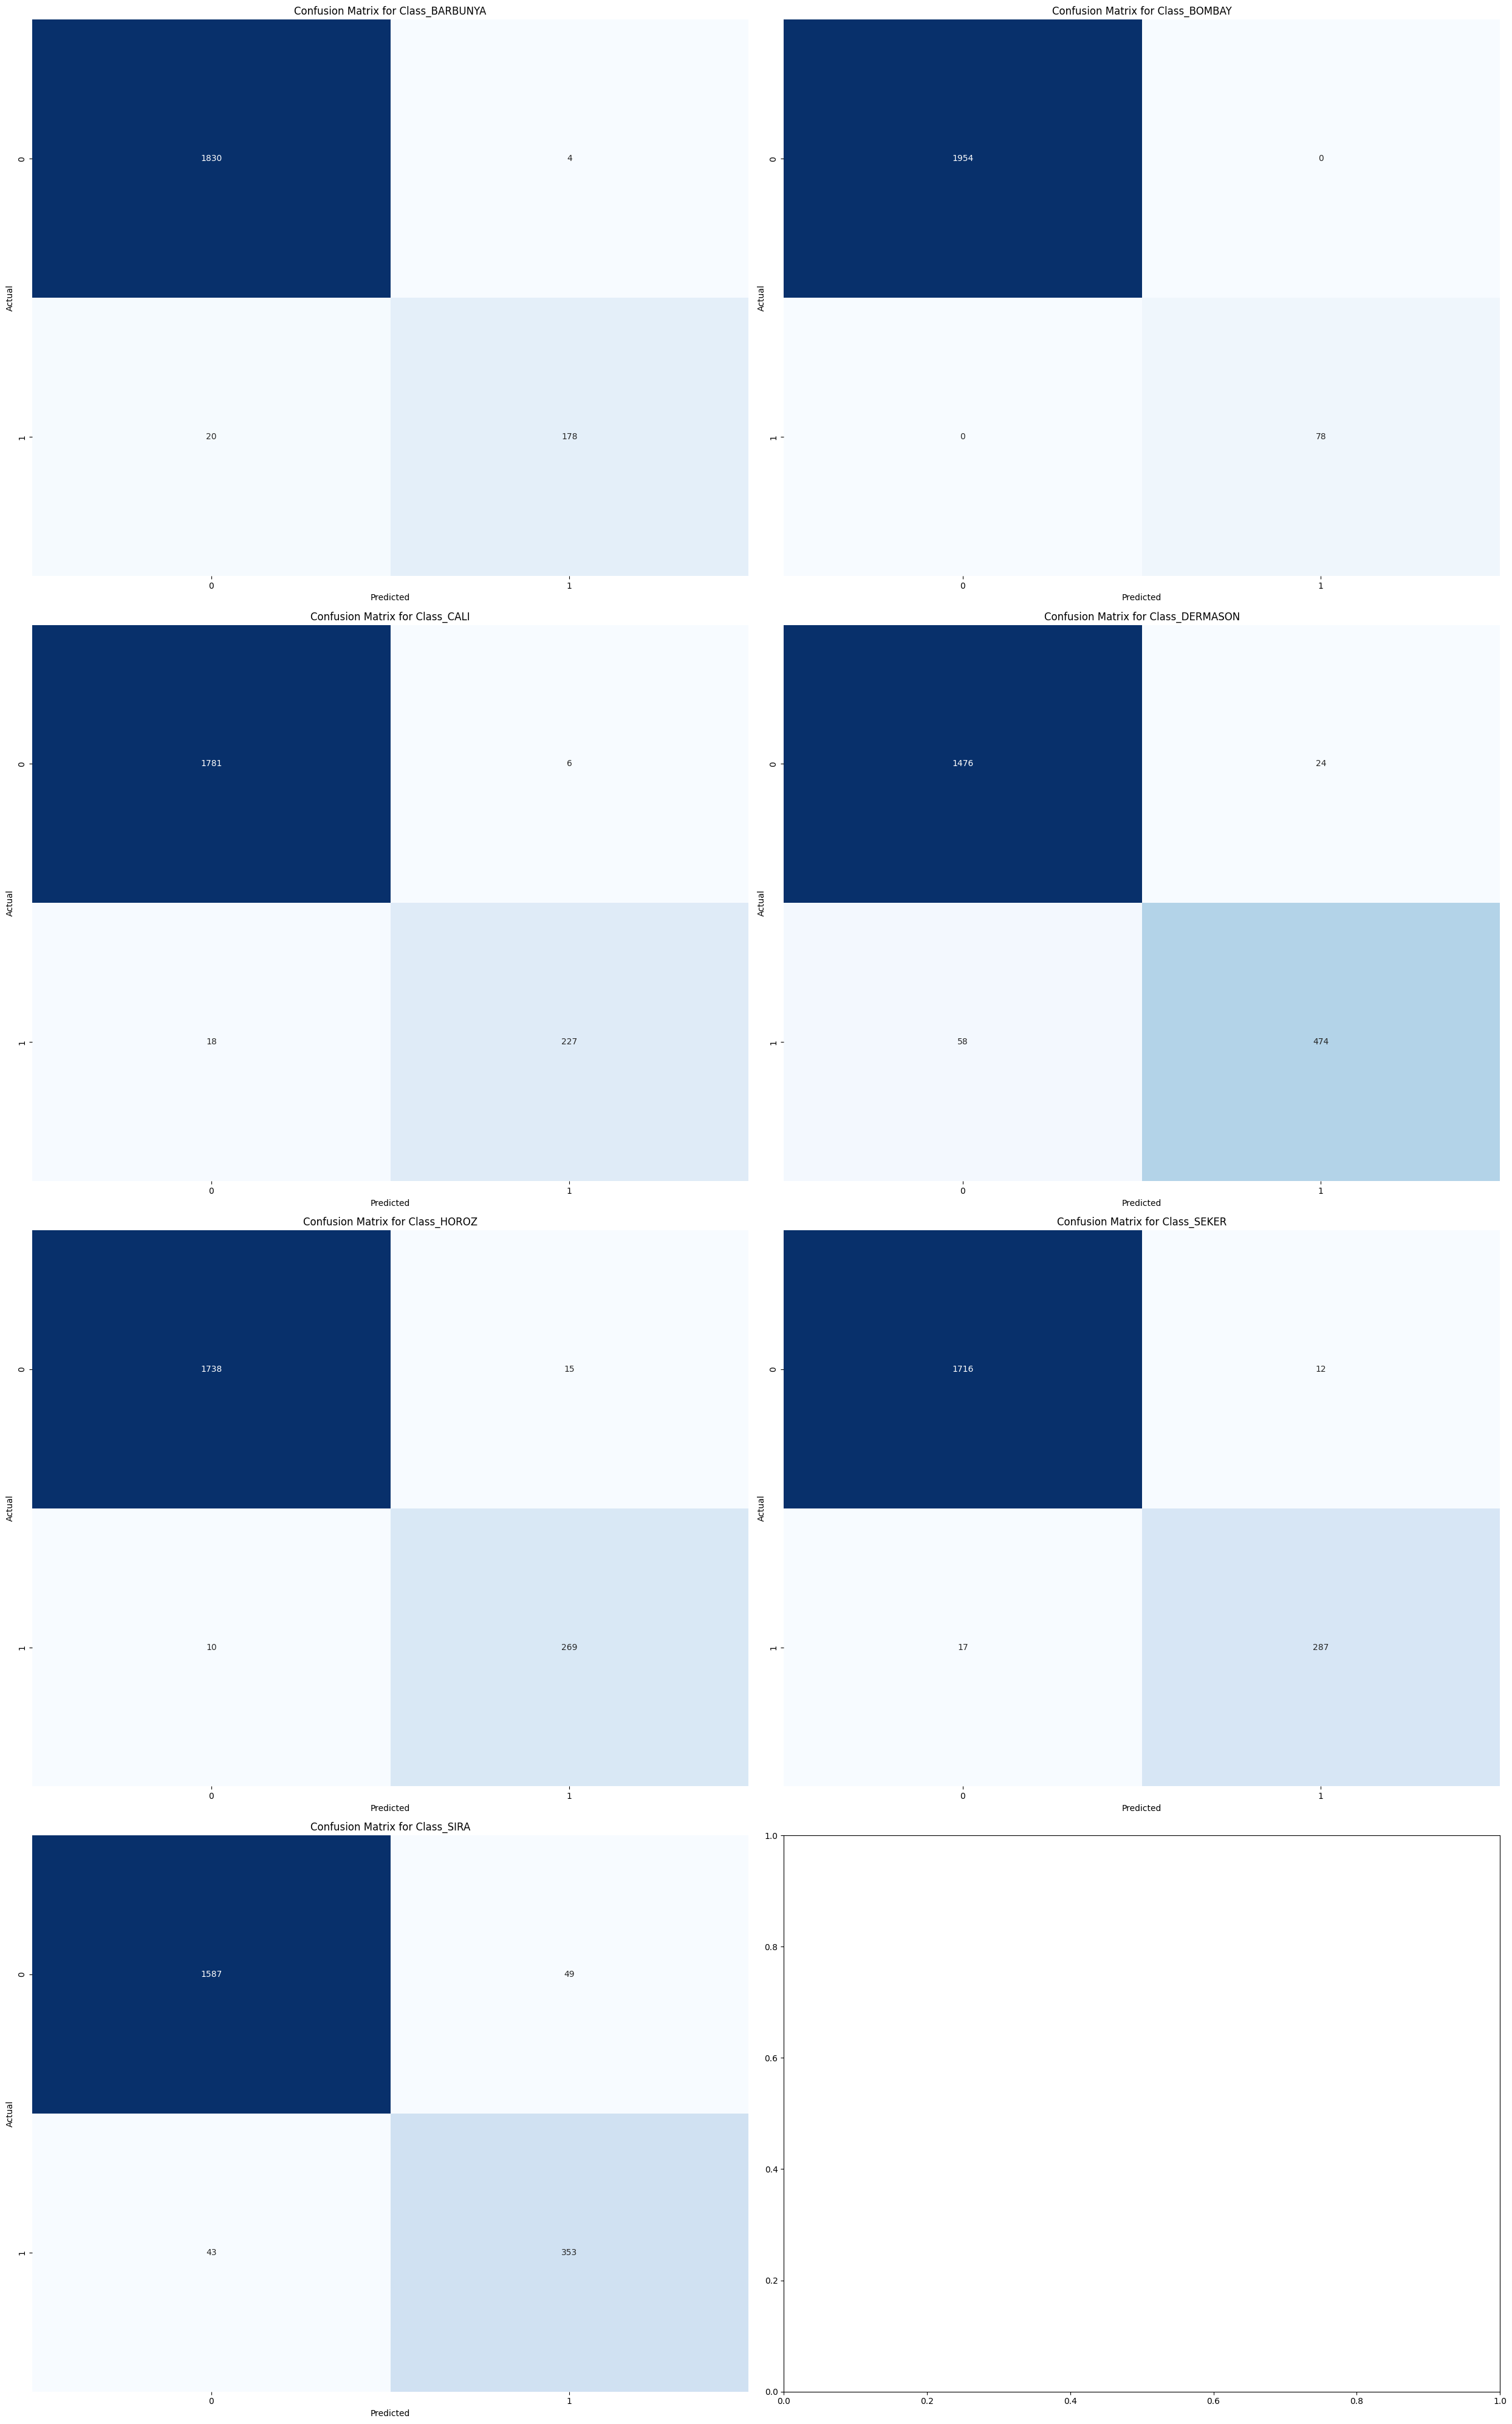

In [65]:
from sklearn.metrics import multilabel_confusion_matrix
conf_matrix = multilabel_confusion_matrix(y_test, y_test_pred3)
labels = y.columns
n_cols = 2
n_rows = 4
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(25, 40))

for i, label in enumerate(labels):
    ax = axes[i // n_cols, i % n_cols]
    sns.heatmap(conf_matrix[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix for {label}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [53]:
init = keras.initializers.HeNormal(seed=42)
ann = keras.models.Sequential()
ann.add(keras.layers.Flatten(input_shape=(12,))) # Input
ann.add(keras.layers.Dense(64, activation="elu", kernel_initializer=init))
ann.add(keras.layers.Dropout(0.5))  # dropout for regularization
ann.add(keras.layers.Dense(7, activation='softmax')) # Output

In [54]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics='accuracy')

In [55]:
ann.summary() # Desc of our model

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 12)                0         
                                                                 
 dense (Dense)               (None, 64)                832       
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 7)                 455       
                                                                 
Total params: 1287 (5.03 KB)
Trainable params: 1287 (5.03 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [56]:
history = ann.fit(X_train, y_train, epochs=20,validation_data=(X_valid, y_valid))

Epoch 1/20


306/306 [==============================] - 2s 3ms/step - loss: 1.2024 - accuracy: 0.6160 - val_loss: 0.3645 - val_accuracy: 0.8935
Epoch 2/20
306/306 [==============================] - 1s 2ms/step - loss: 0.4857 - accuracy: 0.8315 - val_loss: 0.2549 - val_accuracy: 0.9218
Epoch 3/20
306/306 [==============================] - 1s 2ms/step - loss: 0.3729 - accuracy: 0.8703 - val_loss: 0.2249 - val_accuracy: 0.9288
Epoch 4/20
306/306 [==============================] - 1s 2ms/step - loss: 0.3150 - accuracy: 0.8928 - val_loss: 0.2094 - val_accuracy: 0.9294
Epoch 5/20
306/306 [==============================] - 1s 2ms/step - loss: 0.2993 - accuracy: 0.8937 - val_loss: 0.2025 - val_accuracy: 0.9311
Epoch 6/20
306/306 [==============================] - 1s 2ms/step - loss: 0.2817 - accuracy: 0.9012 - val_loss: 0.1986 - val_accuracy: 0.9317
Epoch 7/20
306/306 [==============================] - 1s 2ms/step - loss: 0.2725 - accuracy: 0.9029 - val_loss: 0.1961 - val_accuracy: 0.9334
Epoc

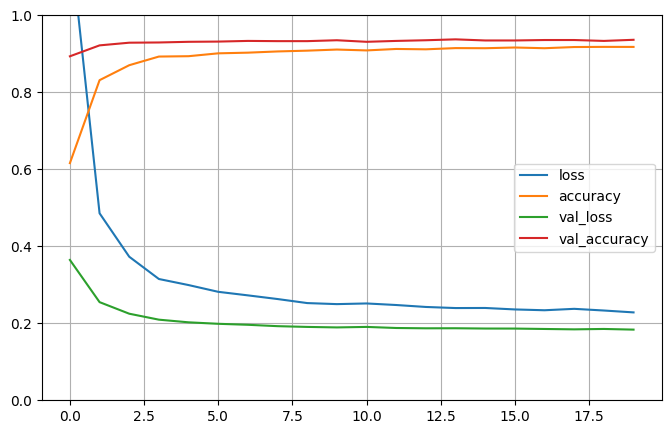

In [57]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show() # To check if our model was overfitting

In [58]:
ann.fit(X_train_, y_train_, epochs=20)

Epoch 1/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2287 - accuracy: 0.9196
Epoch 2/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2264 - accuracy: 0.9203
Epoch 3/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2257 - accuracy: 0.9192
Epoch 4/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2270 - accuracy: 0.9189
Epoch 5/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2255 - accuracy: 0.9190
Epoch 6/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2233 - accuracy: 0.9213
Epoch 7/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2221 - accuracy: 0.9211
Epoch 8/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2236 - accuracy: 0.9225
Epoch 9/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2226 - accuracy: 0.9204
Epoch 10/20
360/360 [==============================] - 1s 2ms/step - loss: 0.2208 - accuracy: 0.9224

In [59]:
ann.evaluate(X_test, y_test)

64/64 [==============================] - 0s 2ms/step - loss: 0.1891 - accuracy: 0.9321


[0.18905587494373322, 0.9320865869522095]

In [60]:
from sklearn.metrics import classification_report
y_pred_prob = ann.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)
cr_4 = classification_report(y_test, y_pred)
print(cr_4)

64/64 [==============================] - 0s 2ms/step
              precision    recall  f1-score   support

           0       0.96      0.91      0.94       198
           1       1.00      1.00      1.00        78
           2       0.96      0.93      0.94       245
           3       0.94      0.92      0.93       532
           4       0.93      0.96      0.95       279
           5       0.94      0.97      0.96       304
           6       0.90      0.88      0.89       396

   micro avg       0.94      0.93      0.93      2032
   macro avg       0.95      0.94      0.94      2032
weighted avg       0.94      0.93      0.93      2032
 samples avg       0.93      0.93      0.93      2032



C:\Users\user\Desktop\Da350_project\ve350\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [61]:
# getting the macro avg. f1 score of the fourth model
lines = cr_4.split('\n')
macro_f1_line = lines[-4]
f1_4 = float(macro_f1_line.split()[4])
f1_4

0.94

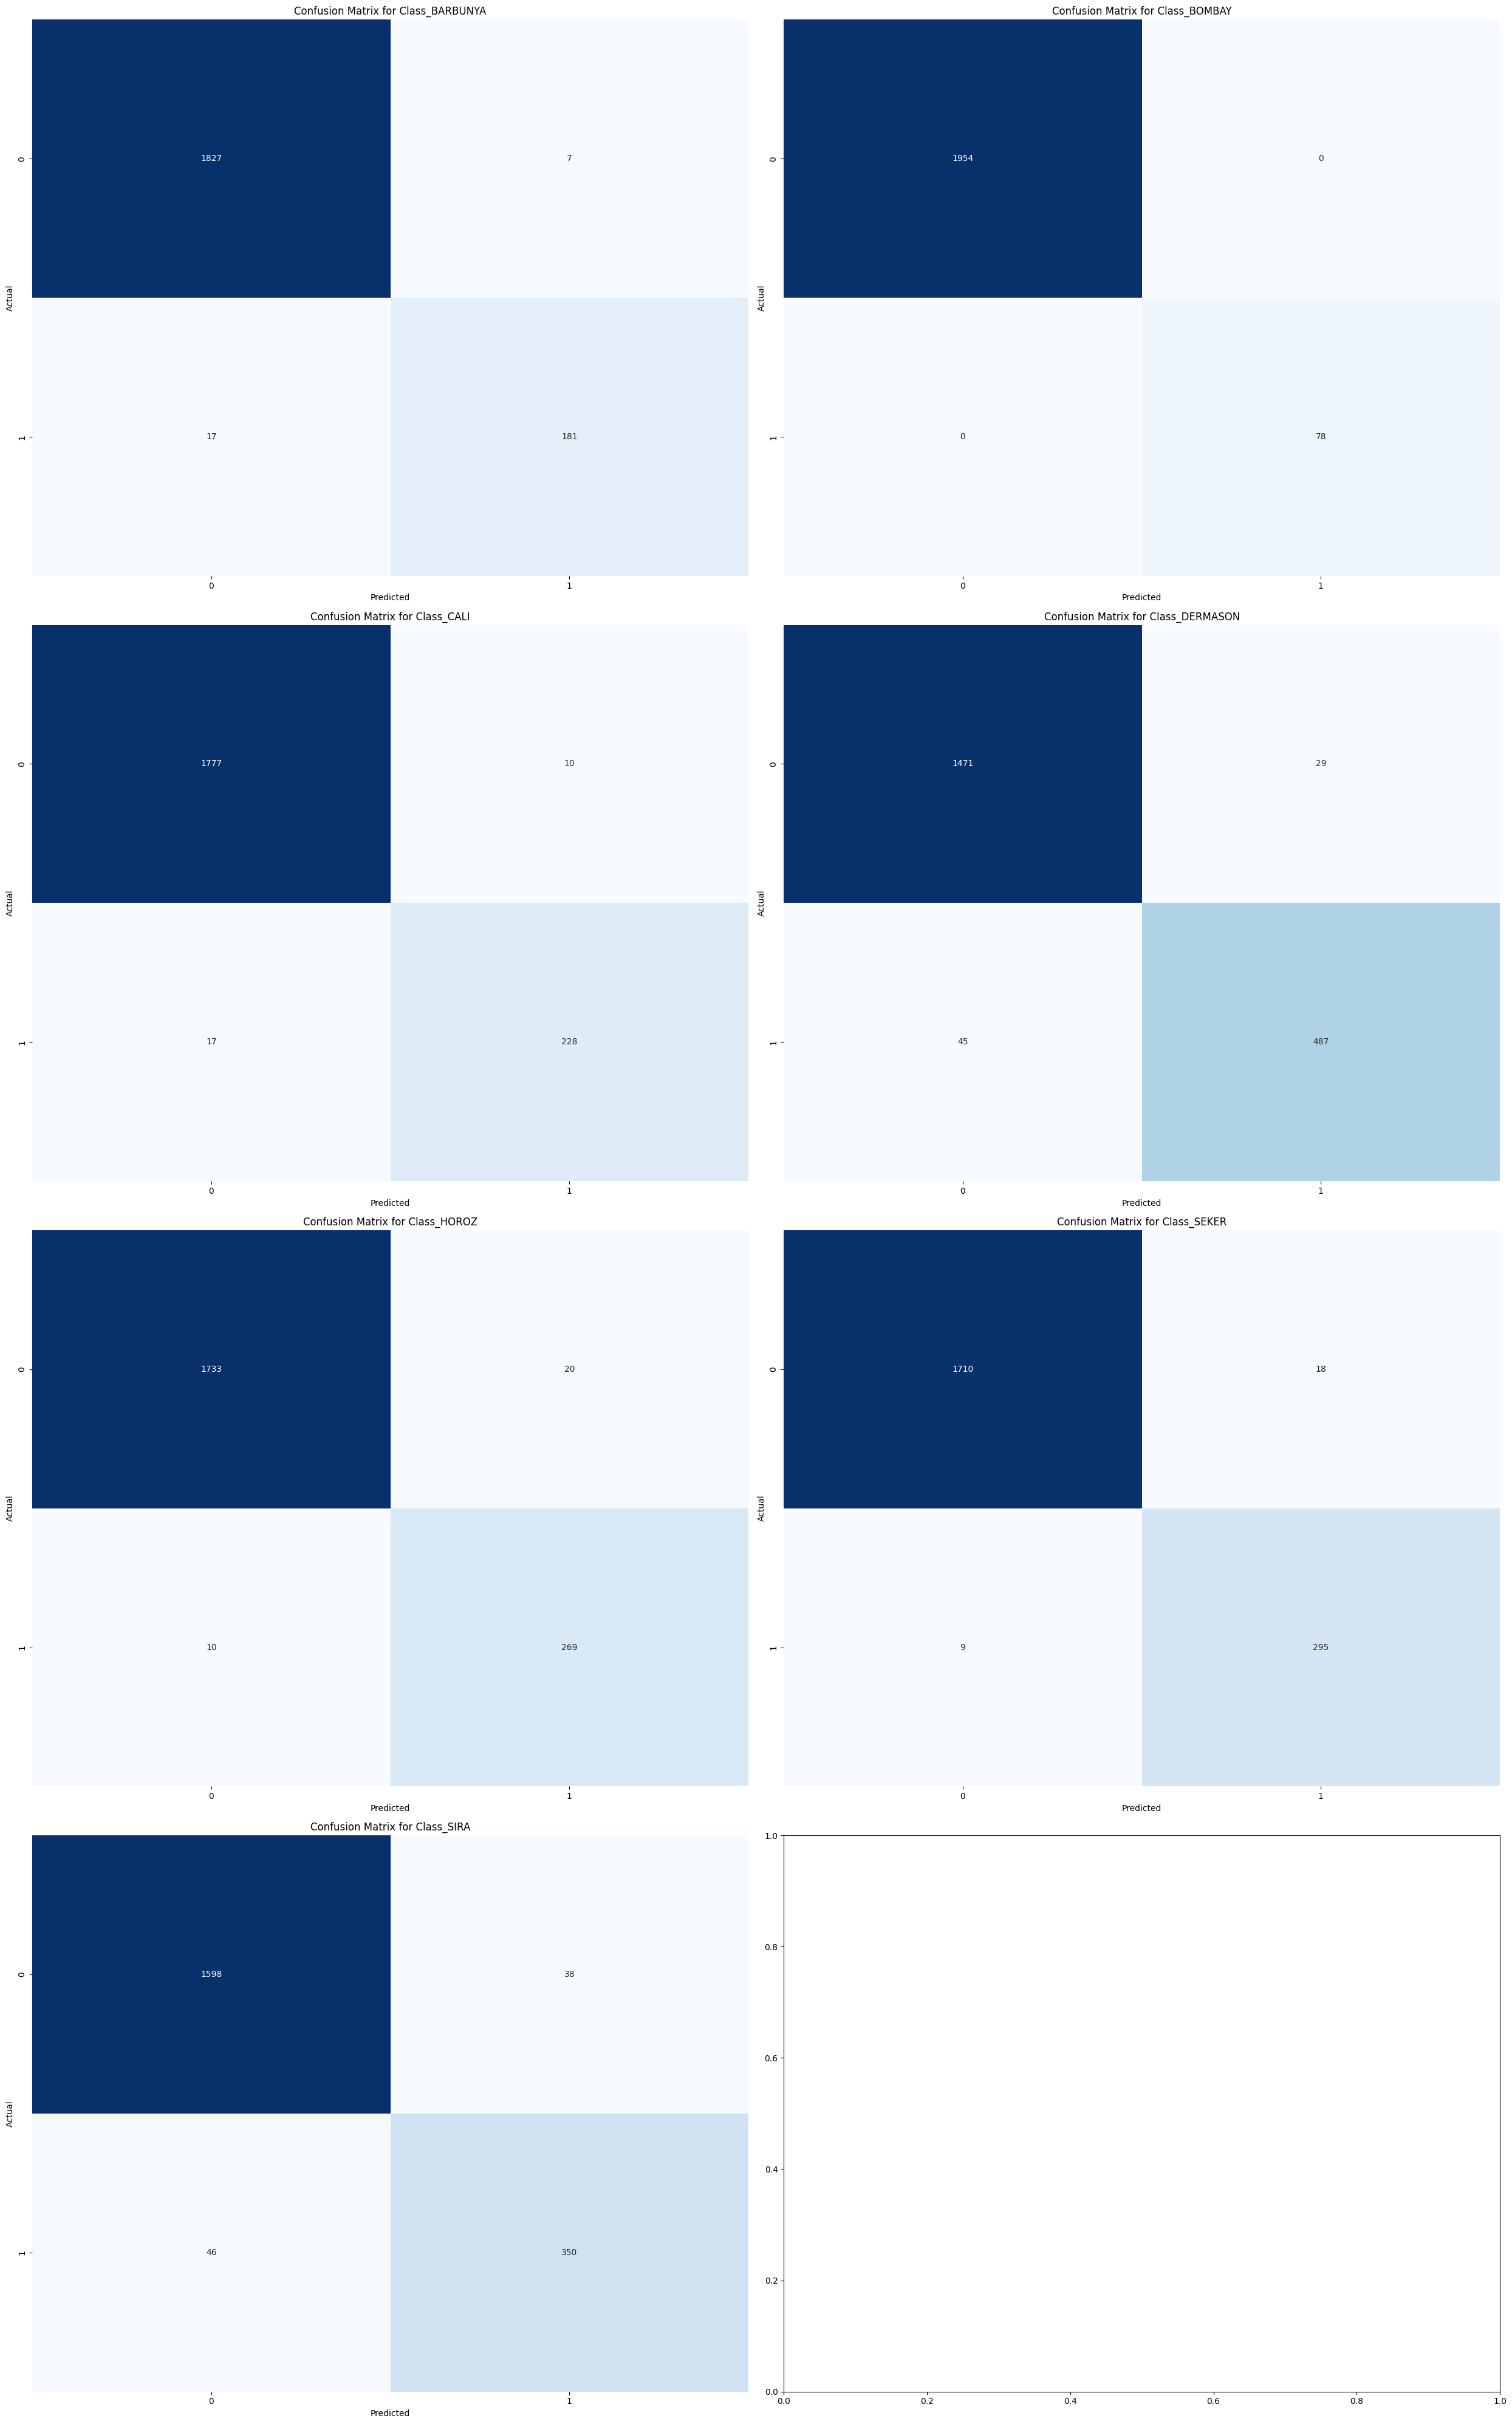

In [67]:
from sklearn.metrics import multilabel_confusion_matrix
conf_matrix = multilabel_confusion_matrix(y_test, y_pred)
labels = y.columns
n_cols = 2
n_rows = 4
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(25, 40))

for i, label in enumerate(labels):
    ax = axes[i // n_cols, i % n_cols]
    sns.heatmap(conf_matrix[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix for {label}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

# **Comparing the scores of the 4 models**

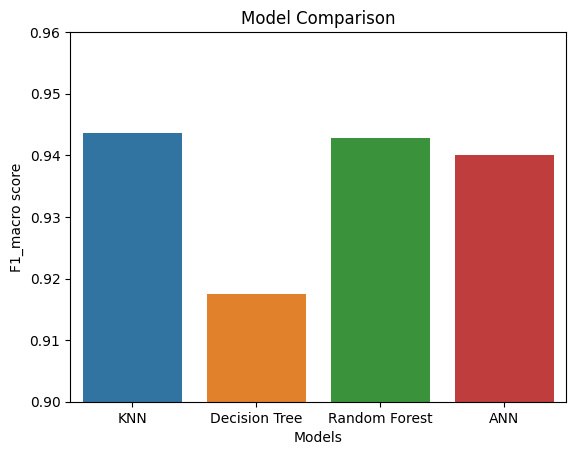

In [62]:
f1 = [f1_1,f1_2,f1_3,f1_4]
models = ['KNN','Decision Tree','Random Forest','ANN']
sns.barplot(x=models,y=f1,hue=models)
plt.gca().set_ylim(0.9, 0.96)
plt.xlabel('Models')
plt.ylabel('F1_macro score')
plt.title('Model Comparison')
plt.show()